# Random Forest

Random Forest Regression (隨機森林迴歸) 是一種監督式機器學習演算法，主要用來預測連續數值 (Continuous Value)。例如：

| 應用情境 | Features (輸入) | Target (預測目標) |
|---|---|---|
| 房屋租金預測 | 坪數、屋齡、樓層、地區 | 每月租金 |
| 汽車價格預測 | 車齡、里程數、品牌 | 二手車價格 |
| 學生成績預測 | 讀書時數、出席率、作業成績 | 期末成績 |
| 商品銷售預測 | 價格、廣告費、促銷次數 | 銷售金額 |

它與 Decision Tree Regression 最大的差別是：
- Decision Tree Regression：建立一棵決策樹，直接使用這棵樹預測。
- Random Forest Regression：建立多棵決策樹，讓每棵樹分別預測，再將預測結果取平均。


## Random Forest Regression 的運作原理

假設我們想預測一間房屋的每月租金，輸入條件如下：

| 房屋條件 | 數值 |
|---|---|
| 房屋坪數 | 25 坪 |
| 屋齡 | 10 年 |
| 距離捷運站 | 500 公尺 |
| 所在樓層 | 6 樓 |

如果只使用一棵 Decision Tree，可能預測每月租金為 22,000 元。

但 Random Forest 會同時建立許多棵決策樹，每棵樹根據訓練過程學到的規則，得到不同預測值。

![](./assets/同一間房屋，交給多棵決策樹預測.png)



## 為什麼多棵樹通常比單棵樹穩定？

因為單棵決策樹容易受到訓練資料的影響，甚至可能發生 Overfitting (過度擬合)。

隨機森林透過兩種隨機機制，讓不同的樹學到不完全相同的規則：
1. Bootstrap Sampling：每棵樹從訓練資料中進行有放回的隨機抽樣。
2. Random Feature Selection：每次節點分裂時，從指定數量的隨機特徵中尋找切割方式。

當多棵樹的預測誤差不完全相同時，取平均就有機會降低模型的變異，改善泛化能力。不過，隨機森林並不保證一定比單棵決策樹準確，仍然需要使用測試資料驗證。

## Random Forest Regression 重要參數

```python
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100, # 建立多少棵決策樹
    max_depth=10, # 限制每棵樹的最大深度
    min_samples_split=2, # 節點至少有多少筆資料才允許分裂
    min_samples_leaf=2, # 每個葉節點至少保留多少筆資料
    max_features=1.0, # 每次分裂時考慮多少特徵
    bootstrap=True, # 是否使用有放回抽樣
    random_state=42, # 固定隨機結果，方便重現
    n_jobs=-1 # 使用多少 CPU 工作程序
)
```

## 實作：使用 Random Forest Regression 預測房屋租金

這次使用一份600 筆模擬房屋租金資料集，讓學生直接練習完整的機器學習流程。

| 欄位名稱 | 中文說明 | 資料型態 |
|---|---|---|
| `area_ping` | 房屋坪數 | 數值 |
| `building_age` | 屋齡 (年) | 數值 |
| `floor` | 所在樓層 | 數值 |
| `distance_to_mrt_m` | 距離捷運站 (公尺) | 數值 |
| `has_parking` | 是否有停車位 (0 / 1) | 數值 |
| `monthly_rent` | 每月租金 (元) | Target |

### 1. 讀取資料集


In [24]:
### 讀取資料集
import pandas as pd

df = pd.read_csv("./data/house_rent_random_forest.csv")

### 2. 探索資料 (EDA)

先不要急著丟進模型，先確認資料長什麼樣


In [25]:
display(df.head())
print("資料形狀：", df.shape)
df.info()
display(df.describe())
display(df.isna().sum().rename("missing_count"))


,area_ping,building_age,floor,distance_to_mrt_m,has_parking,monthly_rent
0,38.1,1,9,1103,0,36855
1,42.8,34,3,1828,0,34462
2,9.4,13,8,2169,0,5500
3,41.0,26,8,1939,1,34586
4,46.0,0,6,1831,1,42159


資料形狀： (600, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   area_ping          600 non-null    float64
 1   building_age       600 non-null    int64  
 2   floor              600 non-null    int64  
 3   distance_to_mrt_m  600 non-null    int64  
 4   has_parking        600 non-null    int64  
 5   monthly_rent       600 non-null    int64  
dtypes: float64(1), int64(5)
memory usage: 28.3 KB


,area_ping,building_age,floor,distance_to_mrt_m,has_parking,monthly_rent
count,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000
mean,32.183167,17.508333,9.626667,1202.118333,0.491667,28972.958333
std,13.563295,10.288003,4.960003,612.503964,0.500348,12050.987576
min,8.100000,0.000000,1.000000,102.000000,0.000000,5500.000000
25%,20.500000,8.000000,5.000000,655.250000,0.000000,18980.000000
50%,32.100000,17.000000,10.000000,1244.000000,0.000000,28213.000000
75%,43.900000,26.000000,14.000000,1741.500000,1.000000,40112.500000
max,55.000000,35.000000,18.000000,2198.000000,1.000000,54665.000000


area_ping            0
building_age         0
floor                0
distance_to_mrt_m    0
has_parking          0
monthly_rent         0
Name: missing_count, dtype: int64

### 3. 資料清理 (Data Cleaning)


In [26]:
import numpy as np


### 資料清理
columns = ["area_ping", "building_age", "floor", "distance_to_mrt_m", "has_parking", "monthly_rent"]

df[columns] = df[columns].apply(pd.to_numeric, errors="coerce") # 將欄位轉為數值，無法轉換的內容設為 NaN
df = df.replace([np.inf, -np.inf], np.nan) # 將正負無限值轉換為 NaN
df = df.dropna(subset=["monthly_rent"]) # 移除 Target 缺失的資料
df = df.drop_duplicates().reset_index(drop=True) # 移除重複資料並重設索引

### 查看清理結果
print(df.isnull().sum()) # 查看各欄位缺失值數量
print("清理後資料筆數：", len(df))

area_ping            0
building_age         0
floor                0
distance_to_mrt_m    0
has_parking          0
monthly_rent         0
dtype: int64
清理後資料筆數： 600


### 4. 選擇 Features 與 Target


In [27]:
### 選擇 Features 與 Target
# 我們希望模型學到以下關係：房屋條件->預測月租金
X = df[[
    "area_ping",
    "building_age",
    "floor",
    "distance_to_mrt_m",
    "has_parking"
]].copy()


### 選擇 Target (預測目標)
y = df["monthly_rent"].copy()

### 5. 切分 Train / Test


In [28]:
### 切分 Train / Test
from sklearn.model_selection import train_test_split

### 切分訓練集 80%、測試集 20%
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2, # 20% 作為測試資料
    random_state=42 # 固定隨機種子
)


### 查看資料筆數
print("Train：", X_train.shape)
print("Test：", X_test.shape)

Train： (480, 5)
Test： (120, 5)


### 6. 建立資料前處理 Pipeline


In [29]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Random Forest 通常不需要標準化，因為決策樹不依賴特徵間的距離
# 數值欄位以中位數補值；二元的 has_parking 以最常見值補值
from sklearn.compose import ColumnTransformer

numeric_features = ["area_ping", "building_age", "floor", "distance_to_mrt_m"]
preprocessor = Pipeline([
    ("imputer", ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median", keep_empty_features=True), numeric_features),
        ("parking", SimpleImputer(strategy="most_frequent", keep_empty_features=True), ["has_parking"])
    ]))
])
# 補值參數會在 model.fit 時只從訓練資料學習，避免資料洩漏


### 7. 建立模型


In [30]:
### 建立 Random Forest Regression 模型
from sklearn.ensemble import RandomForestRegressor
from sklearn import set_config

### 關閉 scikit-learn 模型的 HTML 視覺化顯示
set_config(display="text")

### 建立 Random Forest Regression 模型
regressor = RandomForestRegressor(
    n_estimators=100, # 建立 100 棵決策樹
    max_depth=10, # 每棵樹最大深度為 10
    min_samples_split=2, # 節點至少 2 筆資料才允許分裂
    min_samples_leaf=2, # 每個葉節點至少保留 2 筆資料
    max_features=1.0, # 每次分裂考慮全部 Features
    bootstrap=True, # 使用 Bootstrap 抽樣
    random_state=42, # 固定隨機種子
    n_jobs=-1 # 使用所有可用 CPU 工作程序
)


# 將補值與模型串接，預測時會自動套用相同的前處理
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", regressor)
])


### 8. 訓練模型


In [31]:
model.fit(X_train, y_train)
print("模型訓練完成")


模型訓練完成


### 9. 使用模型預測


In [32]:
### 使用模型預測
y_pred = model.predict(X_test)


### 比較實際租金與預測租金
result = pd.DataFrame({
    "實際租金": y_test.values,
    "預測租金": y_pred
})


### 查看前 10 筆預測結果
display(result.head(10))

,實際租金,預測租金
0,46092,44290.111190
1,48929,45969.661505
2,16911,18053.445016
3,47743,45764.436326
4,24574,23684.492512
5,31435,27757.955817
6,21872,21505.349029
7,19052,15363.113333
8,41699,42195.973333
9,14706,14706.449738


### 10. 評估模型表現


In [33]:
### 評估模型表現
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


### 計算評估指標
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)


### 顯示評估結果
print(f"MAE：{mae:.2f}") # 越小越好
print(f"MSE：{mse:.2f}") # 越小越好
print(f"RMSE：{rmse:.2f}") # 越小越好
print(f"R²：{r2:.4f}") # 越接近 1 越好

MAE：1623.23
MSE：4148272.34
RMSE：2036.73
R²：0.9725


### 11. 視覺化預測結果


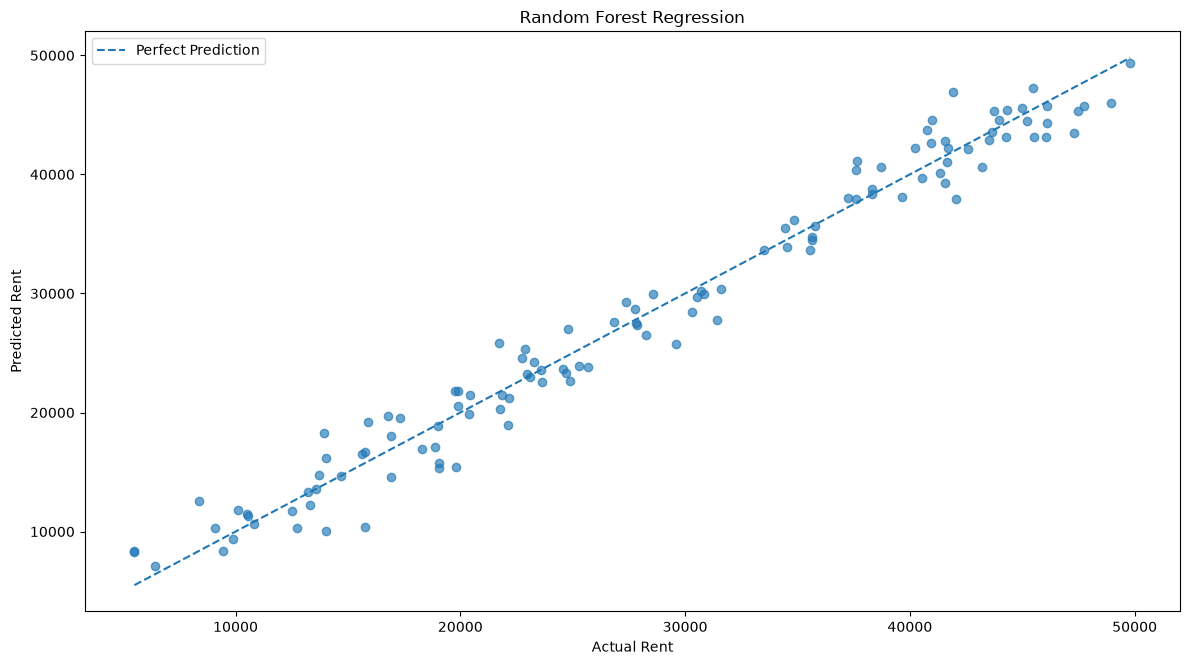

In [34]:
### 視覺化預測結果
import matplotlib.pyplot as plt


### 建立圖表
plt.figure(figsize=(12, 6.75))


### 繪製實際值與預測值
plt.scatter(y_test, y_pred, alpha=0.65)


### 繪製理想預測線
limits = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]

plt.plot(limits, limits, "--", label="Perfect Prediction")


### 設定圖表
plt.xlabel("Actual Rent")
plt.ylabel("Predicted Rent")
plt.title("Random Forest Regression")
plt.legend()
plt.tight_layout()
plt.show()

## 作業：使用 Random Forest Regression 預測臺灣空氣品質指標 (AQI)

本次作業使用政府資料開放平臺提供的「空氣品質指標(AQI)(歷史資料)」，並使用 Random Forest Regression (隨機森林迴歸) 建立模型，預測臺灣各空氣品質監測站的 AQI 數值。

- 資料集：[空氣品質指標(AQI)(歷史資料)](https://data.gov.tw/dataset/151824)

模型根據空氣中的污染物濃度與氣象條件，例如：

```text
PM2.5 細懸浮微粒濃度
PM10 懸浮微粒濃度
O3 臭氧濃度
NO2 二氧化氮濃度
SO2 二氧化硫濃度
CO 一氧化碳濃度
風速
```

預測：
```text
AQI 空氣品質指標
```

建立以下關係：
$$
\boxed{
\text{空氣污染物與氣象數據}
\longrightarrow
\text{Random Forest Regression}
\longrightarrow
\text{預測 AQI}
}
$$

AQI 本身就是依污染物監測數值計算出來的指標，因此這次作業主要訓練學生使用 Random Forest 重建數值關係，並不是預測未來的空氣品質。

學生必須按照以下順序完成：
```text
1. Pandas 讀取政府開放資料
        ↓
2. 查看資料 (head / info / describe)
        ↓
3. 資料清理
        ↓
4. 選擇 Features / Target
        ↓
6. Train / Validation / Test Split
        ↓
7. 建立 Random Forest Regression
        ↓
8. 訓練 Random Forest Regression
        ↓
9. 使用 Validation Data 進行預測
        ↓
10. 驗收：MAE / RMSE / R²
        ↓
16. 視覺化實際 AQI vs 預測 AQI
        ↓
17. 視覺化 Feature Importance
```

<p style="text-align: center;">Copyright © 2026 Wei-Cheng Chen</p>